# Atmospheric correction with TRISHNA bands (GRS)

## Requirements
- An L1C Sentinel-2 image (SAFE) and the matching CAMS file (GRS input).
- The GRS look-up tables (downloaded by `grs` at first use).

## Tutorial objectives
- Run GRS on a Sentinel-2 image restricted to the TRISHNA-like bands.
- Compare with GRS run on all the S2 bands: Rrs and aerosol optical thickness.
- Quantify the sensitivity of the TRISHNA-band Rrs to an aerosol error.

## Environment
Use the `sandbox_env` kernel of the CNES JupyterHub. Otherwise install the packages below in your environment (the `trishna_tbx` toolbox: `pip install -e <path>/trishna_tbx`):

`GRSdriver`, `grs`, `GRSl2bgen`, `radcalnet_oc`, `invRrs`, `trishna_tbx`, `matplotlib`, `pandas`, `xarray`.

## Resources
The code can be executed with the CPU: 4 cores, 8 GB. Run time: ~25 min for the 3 GRS runs (cached in OUTPUT_DIR).

![version](https://img.shields.io/badge/version-11.2026-blue)

## Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import trishna_tbx
from trishna_tbx import TRISHNA, make_s2
print('trishna_tbx', trishna_tbx.__version__)
from pathlib import Path
THUMB_DIR = Path('../thumbnails').resolve() if Path('../thumbnails').exists() else Path('.').resolve()
# plot style: Times-like serif fonts with LaTeX-style math (STIX, no TeX installation needed),
# larger fonts, minor ticks on all axes
plt.rcParams.update({'figure.dpi': 90, 'font.size': 14, 'font.family': 'STIXGeneral',
                     'mathtext.fontset': 'stix', 'axes.titlesize': 15, 'axes.labelsize': 15,
                     'legend.fontsize': 12, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
                     'xtick.minor.visible': True, 'ytick.minor.visible': True})

from GRSdriver import Sentinel2Driver
from trishna_tbx.emulate import open_s2_l1c_as_trishna

trishna_tbx 0.0.1


## Data
> **Data paths.** On the CNES JupyterHub, point the variables below to the TREX datalake or to your project space. Outside CNES, download Sentinel-2 L1C with the *Access data - Copernicus API* tutorial. Each path can also be set through the environment variable named in the cell.

In [2]:
import os
from pathlib import Path

# ---- edit here (or set the environment variables) ------------------------------------
S2_L1C = os.environ.get('TRISHNA_TBX_S2_L1C',
    '/data/satellite/Sentinel-2/L1C/31TFJ/2025/05/26/'
    'S2B_MSIL1C_20250526T103629_N0511_R008_T31TFJ_20250526T123708.SAFE')
CAMS_FILE = os.environ.get('TRISHNA_TBX_CAMS', '/data/cams/world/cams_forecast_2025-05.nc')
# 30 km box (UTM 31N) over the Berre lagoon and the eastern Gulf of Fos
SUBSET = [(655000, 4800000, 685000, 4830000)]
L2A_DIR = os.environ.get('TRISHNA_TBX_L2A_DIR',
    '/home/harmel/Dropbox/Dropbox/work/projet/unesco/satellite/L2A')  # GRS L2A (beam profile)
L2A_TILE = 'T33PVQ'                      # Lake Chad (southern pool)
L2A_WINDOW = 'y=0:3600,x=0:960'          # 20 m pixel window with water
L2A_DATE = '2022-02-12'                  # date used by the single-image tutorials
# single-image example of the products tutorial: Loire estuary and plume, GRS v3.1.1 (Zarr pyramid,
# local S3 bucket grstbx-s3 of grstbx, read here through its folder)
L2A_EXAMPLE = os.environ.get('TRISHNA_TBX_L2A_EXAMPLE',
    '/data/satellite/s3/grstbx-s3/sentinel-2/l2a/30TWT/2017/04/12/'
    'S2A_MSIL2AGRS_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.1.1/'
    'S2A_MSIL2AGRS_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.1.1.zarr')
L2A_EXAMPLE_WINDOW = 'y=2700:5490,x=1500:4500'   # 20 m pixels: estuary, plume, Bourgneuf Bay
L2B_EXAMPLE = os.environ.get('TRISHNA_TBX_L2B_EXAMPLE',   # GRSl2bgen L2B of the same image
    '/data/satellite/s3/grstbx-s3/sentinel-2/l2b/30TWT/2017/04/12/'
    'S2A_MSIL2B_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.1.1/'
    'S2A_MSIL2B_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.1.1.zarr')
AERONET_HYP_DIR = os.environ.get('TRISHNA_TBX_AERONET_HYP', '/DATA/AERONET/OCv3_invRrs/data')
OUTPUT_DIR = Path(os.environ.get('TRISHNA_TBX_OUTPUT', './output')).resolve()
# ---------------------------------------------------------------------------------------
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. What changes for GRS with TRISHNA bands
GRS (Harmel et al. 2018) retrieves the aerosol load and the sunglint from the **two
longest-wavelength processed bands**:
- full Sentinel-2: 1610 and 2190 nm (SWIR),
- TRISHNA: 865 and 1610 nm (NIR + SWIR), since there is no 2190 nm band.

The 2190 nm band is still loaded (not processed) because the GRS "high SWIR" mask needs it;
this dependency has to be removed in GRS for real TRISHNA data. Water vapour comes from CAMS
in both cases (see *Water vapour with TRISHNA*).

In [3]:
import logging
import grs
logging.getLogger().setLevel(logging.WARNING)   # GRS logs at INFO level

def clean_attrs(ds):
    """NetCDF-safe attributes (GRS attributes may hold booleans/lists)."""
    ds = ds.copy()
    for v in ds.variables.values():
        v.attrs = {k: (str(a) if not isinstance(a, (int, float, str)) or isinstance(a, bool) else a)
                   for k, a in v.attrs.items()}
    ds.attrs = {k: (str(a) if not isinstance(a, (int, float, str)) or isinstance(a, bool) else a)
                for k, a in ds.attrs.items()}
    return ds

def run_grs(prod, name, **kw):
    """Run GRS at 60 m (or reload the cached result)."""
    f = OUTPUT_DIR / f'grs_{name}.nc'
    if f.exists():
        return xr.open_dataset(f)
    p = grs.Process()
    p.execute(prod, odir=str(OUTPUT_DIR / name), cams_file=CAMS_FILE, resolution=60, **kw)
    l2 = p.l2a.l2_prod[['Rrs', 'aot550', 'mask', 'flags']].load()
    l2 = l2.assign_coords(wl=l2.wl.astype(int))
    clean_attrs(l2).to_netcdf(f)
    return xr.open_dataset(f)

## 2. Load the L1C products and run GRS

In [4]:
prod_tri = open_s2_l1c_as_trishna(S2_L1C, resolution=60, subset=SUBSET)
drv = Sentinel2Driver(S2_L1C, resolution=60, resolution_angle=60, subset=SUBSET)
drv.load_product()
prod_s2 = drv.prod
print('TRISHNA-like processed bands:', prod_tri.attrs['wl_to_process'])
print('S2 processed bands          :', prod_s2.attrs['wl_to_process'])

TRISHNA-like processed bands: [ 490  560  665  865 1610]
S2 processed bands          : [ 443  490  560  665  705  740  783  842  865 1610 2190]


In [5]:
%%time
l2_tri = run_grs(prod_tri, 'trishna')
l2_s2 = run_grs(prod_s2, 's2')

CPU times: user 150 ms, sys: 27.4 ms, total: 178 ms
Wall time: 225 ms


## 3. Rrs maps
Water pixels are those flagged as water by GRS (`mask == 0`) in both runs.

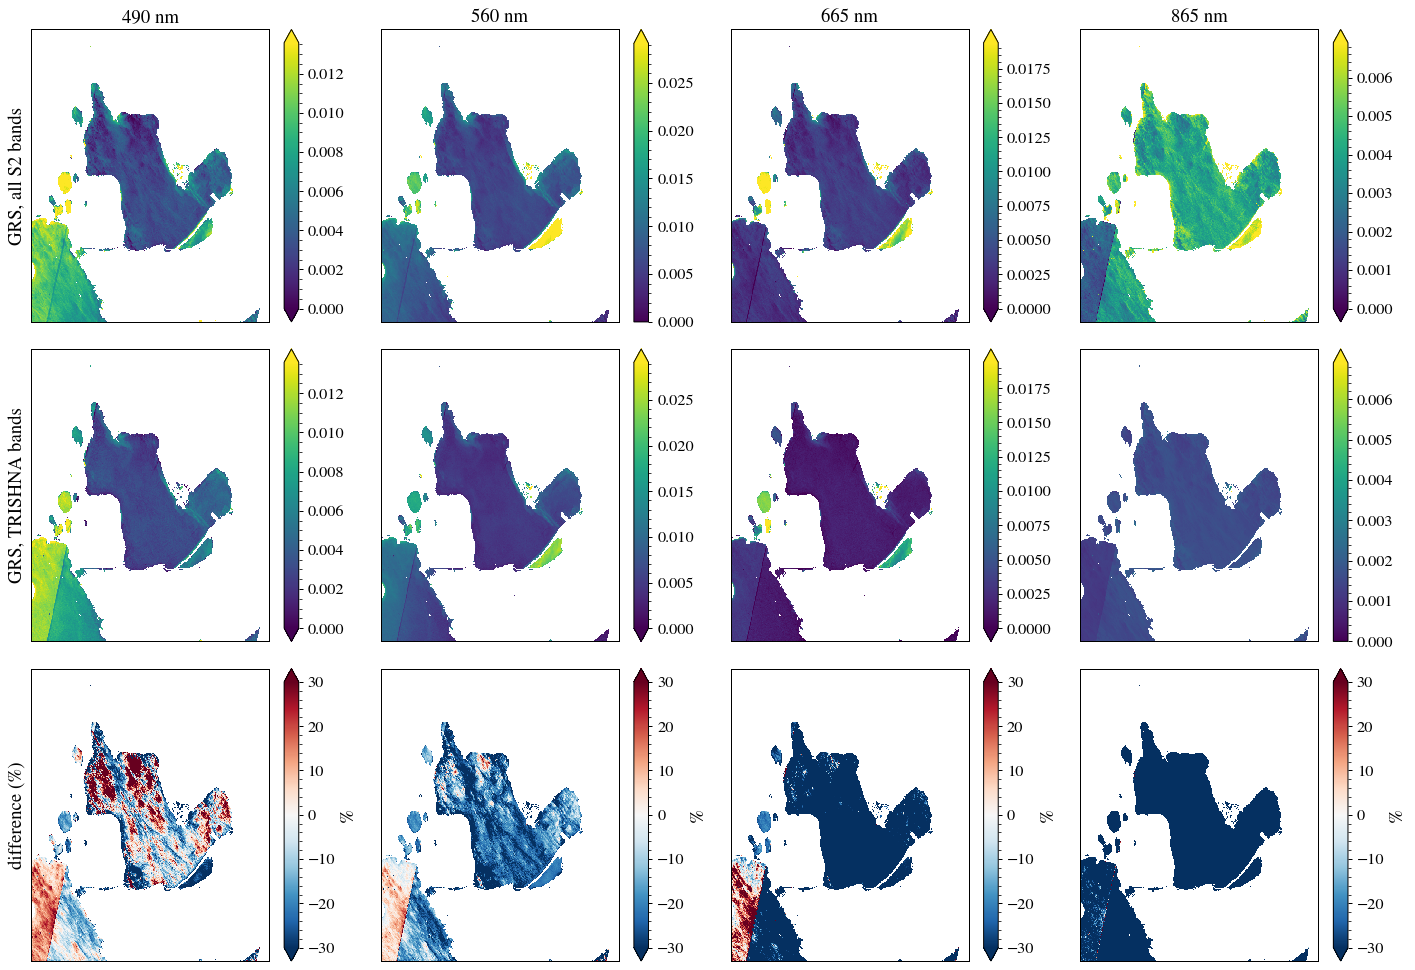

In [6]:
water = (l2_tri.mask == 0) & (l2_s2.mask == 0)
common = [490, 560, 665, 865]
fig, axs = plt.subplots(3, 4, figsize=(16, 11), sharex=True, sharey=True)
for j, w in enumerate(common):
    a = l2_s2.Rrs.sel(wl=w).where(water)
    b = l2_tri.Rrs.sel(wl=w).where(water)
    vmax = float(a.quantile(0.98))
    a.plot(ax=axs[0, j], vmin=0, vmax=vmax, cmap='viridis', add_labels=False)
    b.plot(ax=axs[1, j], vmin=0, vmax=vmax, cmap='viridis', add_labels=False)
    (100 * (b - a) / a).plot(ax=axs[2, j], vmin=-30, vmax=30, cmap='RdBu_r', add_labels=False,
                              cbar_kwargs={'label': '%'})
    axs[0, j].set_title(f'{w} nm')
for i, t in enumerate(['GRS, all S2 bands', 'GRS, TRISHNA bands', 'difference (%)']):
    axs[i, 0].set_ylabel(t)
for ax in axs.ravel():
    ax.set_xticks([]); ax.set_yticks([]); ax.minorticks_off()
fig.tight_layout()
fig.savefig(THUMB_DIR / 'grs_trishna_bands.png', dpi=60)

## 4. Band-by-band comparison and aerosol optical thickness

,median bias (sr-1),MdAPD (%),r,N
490,-0.00013,13.78926,0.88351,66629.0
560,-0.00142,20.64821,0.93549,66629.0
665,-0.00174,50.80910,0.94087,66629.0
865,-0.00244,60.98035,0.88651,66629.0


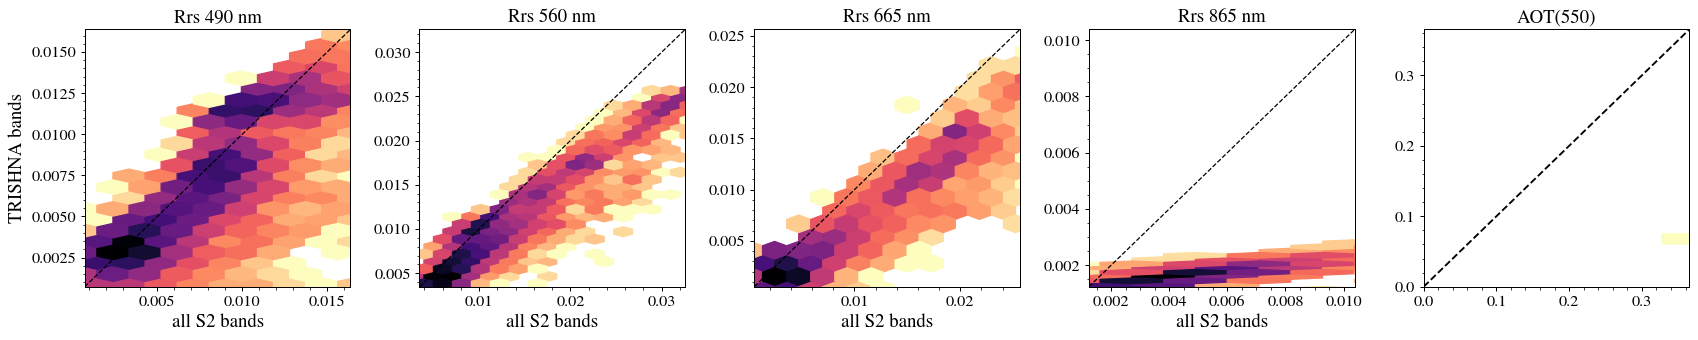

In [7]:
rows = {}
fig, axs = plt.subplots(1, 5, figsize=(19, 4))
for ax, w in zip(axs, common):
    a = l2_s2.Rrs.sel(wl=w).where(water).values.ravel()
    b = l2_tri.Rrs.sel(wl=w).where(water).values.ravel()
    ok = np.isfinite(a) & np.isfinite(b)
    ax.hexbin(a[ok], b[ok], gridsize=60, bins='log', cmap='magma_r')
    lim = np.nanpercentile(a[ok], [0.5, 99.5]); ax.plot(lim, lim, 'k--', lw=1)
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_title(f'Rrs {w} nm'); ax.set_xlabel('all S2 bands')
    rows[w] = {'median bias (sr-1)': np.median(b[ok] - a[ok]), 'MdAPD (%)': 100 * np.median(np.abs(b[ok] - a[ok]) / np.abs(a[ok])),
               'r': np.corrcoef(a[ok], b[ok])[0, 1], 'N': ok.sum()}
axs[0].set_ylabel('TRISHNA bands')
a, b = l2_s2.aot550.where(water).values.ravel(), l2_tri.aot550.where(water).values.ravel()
ok = np.isfinite(a) & np.isfinite(b)
axs[4].hexbin(a[ok], b[ok], gridsize=40, bins='log', cmap='magma_r'); axs[4].plot([0, 1], [0, 1], 'k--')
axs[4].set_xlim(0, np.nanpercentile(a, 99)); axs[4].set_ylim(0, np.nanpercentile(a, 99)); axs[4].set_title('AOT(550)')
fig.tight_layout()
pd.DataFrame(rows).T.round(5)

In [8]:
from pyproj import Transformer
from trishna_tbx.io import cams_value
lon, lat = Transformer.from_crs(32631, 4326, always_xy=True).transform(float(l2_tri.x.mean()), float(l2_tri.y.mean()))
aod_cams = float(cams_value(CAMS_FILE, 'aod550', prod_tri.time.values, lon, lat)[0])
pd.Series({'CAMS aod550 (first guess)': aod_cams,
           'GRS AOT, TRISHNA bands (865/1610)': float(l2_tri.aot550.where(water).median()),
           'GRS AOT, all S2 bands (1610/2190)': float(l2_s2.aot550.where(water).median())}).round(3)

CAMS aod550 (first guess)            0.043
GRS AOT, TRISHNA bands (865/1610)    0.068
GRS AOT, all S2 bands (1610/2190)    0.365
dtype: float64

On the default scene (26 May 2025, strong sunglint over the Berre lagoon), the two band sets
give very different AOT: the TRISHNA pair (865/1610 nm) stays close to CAMS while the S2 SWIR
pair (1610/2190 nm) gives a much higher value, and the red/NIR Rrs differ accordingly. The aerosol
and the sunglint are retrieved jointly from these two bands: under strong glint the partition
between both is sensitive to the band pair. This single case does not tell which is right:
matchups with AERONET-OC / HYPERNETS are needed (see the *Validation* section).

## 5. Sensitivity to the aerosol model and to the sunglint handling
Two GRS options are tested with both band sets:
- `opac_model='MACL_rh70'`: force a maritime aerosol model (by default it is chosen from CAMS);
- `glint_aot=True`: hybrid AOT retrieval for blocks under strong sunglint (recent grs versions only).

For a broader sensitivity study (AOT, aerosol type, H2O, O3) at lower cost, use the
simulations of *Top-of-atmosphere simulations with RadCalNet-OC*.

In [9]:
%%time
import inspect
runs = {('TRISHNA', 'default'): l2_tri, ('S2', 'default'): l2_s2,
        ('TRISHNA', 'maritime aerosol'): run_grs(prod_tri, 'trishna_macl', opac_model='MACL_rh70')}
if 'glint_aot' in inspect.signature(grs.Process.execute).parameters:
    runs[('TRISHNA', 'glint_aot')] = run_grs(prod_tri, 'trishna_glintaot', glint_aot=True)
    runs[('S2', 'glint_aot')] = run_grs(prod_s2, 's2_glintaot', glint_aot=True)
else:
    print(f'grs {grs.__version__}: no glint_aot option (needs a recent grs), skipped')
rows = {}
for (bands_, case), l2 in runs.items():
    w = water & (l2.mask == 0)
    r = {f'Rrs {wl}': float(l2.Rrs.sel(wl=wl).where(w).median()) for wl in common}
    r['AOT(550)'] = float(l2.aot550.where(w).median())
    rows[(bands_, case)] = r
pd.DataFrame(rows).T.round(5)

grs 3.1.1: no glint_aot option (needs a recent grs), skipped
CPU times: user 270 ms, sys: 36.9 ms, total: 307 ms
Wall time: 314 ms


,,Rrs 490,Rrs 560,Rrs 665,Rrs 865,AOT(550)
TRISHNA,default,0.00359,0.00523,0.00162,0.00157,0.06788
S2,default,0.00401,0.00687,0.00332,0.00401,0.36521
TRISHNA,maritime aerosol,0.00319,0.00482,0.00136,0.00144,0.06788


## Take-home messages
- GRS runs on the TRISHNA band set without code change, using 865/1610 nm for the aerosol
  and glint retrieval.
- The aerosol/glint band pair matters: under strong glint the AOT and the red/NIR Rrs can differ
  a lot between the TRISHNA and S2 band sets; in turbid waters the 865 nm water signal is not
  zero and can bias the TRISHNA aerosol retrieval. Validation on in situ matchups is needed.
- For real TRISHNA products, GRS needs: no dependency on 2190 nm for masking, the TRISHNA
  SRF (`wl_true`), and an image-based water vapour (910 nm band).

## References
- Harmel, T. et al. (2018), Sunglint correction of the Multi-Spectral Instrument (MSI)-SENTINEL-2 imagery over inland and sea waters from SWIR bands, RSE 204.